<a href="https://colab.research.google.com/github/rodrigodacunhaconceicao/parking-garage-occupancy-original/blob/main/MultivariateProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Necessary Installs
!pip install -q factor_analyzer "pingouin==0.5.5"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
#Necessary Imports
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator
from factor_analyzer import FactorAnalyzer
import pingouin as pg
from numpy.linalg import inv
from sklearn.impute import KNNImputer #new
from pandas.core.arrays import numeric #new
import seaborn as sns #new


In [74]:
#Import data

df1 = pd.read_excel("dataset_18_24.xlt", na_values = [":", "#N/A"])
df2 = pd.read_excel("dataset_25_49.xlt", na_values = [":", "#N/A"])
df3 = pd.read_excel("dataset_50_65.xlt", na_values = [":", "#N/A"])
df4 = pd.read_excel("dataset_65plus.xlt", na_values = [":", "#N/A"])

ue_countries = [
    "Austria", "Belgium", "Bulgaria", "Croatia", "Cyprus",
    "Czechia", "Denmark", "Estonia", "Finland", "France",
    "Germany", "Greece", "Hungary", "Ireland", "Italy",
    "Latvia", "Lithuania", "Luxembourg", "Malta", "Netherlands",
    "Poland", "Portugal", "Romania", "Slovakia", "Slovenia",
    "Spain", "Sweden"
]

df1 = df1[df1["Country"].isin(ue_countries)]
df2 = df2[df2["Country"].isin(ue_countries)]
df3 = df3[df3["Country"].isin(ue_countries)]
df4 = df4[df4["Country"].isin(ue_countries)]

df1["Country"] = df1["Country"] + str("18_24")
df2["Country"] = df2["Country"] + str("25_49")
df3["Country"] = df3["Country"] + str("50_65")
df4["Country"] = df4["Country"] + str("65plus")

df = pd.concat([df1, df2, df3, df4], ignore_index = True)

In [75]:
display(df)
display(df.head())


,Country,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,voluntary_act%,trust%,hours_work
0,Luxembourg18_24,42281.0,27.6,57.5,96.8,93.8,33.1,8.5,6.4,33.440
1,Ireland18_24,32885.0,47.4,70.3,96.6,85.9,27.4,13.6,7.0,27.261
2,Denmark18_24,29647.0,56.1,25.7,85.9,91.5,20.8,24.4,5.3,20.917
3,Austria18_24,28331.0,51.9,59.2,99.0,82.8,35.3,8.1,5.5,33.589
4,Belgium18_24,28096.0,26.0,60.5,98.4,82.3,45.0,10.1,6.8,29.370
...,...,...,...,...,...,...,...,...,...,...
103,Romania65plus,5987.0,3.2,1.7,90.1,6.9,28.0,1.5,6.8,NaN
104,Slovenia65plus,15579.0,7.0,5.6,94.3,40.4,34.2,25.5,4.4,29.829
105,Slovakia65plus,8935.0,6.9,0.9,92.5,16.9,33.1,6.3,5.9,NaN
106,Finland65plus,25752.0,13.3,5.0,92.2,51.4,41.3,NaN,7.0,23.189


,Country,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,voluntary_act%,trust%,hours_work
0,Luxembourg18_24,42281.0,27.6,57.5,96.8,93.8,33.1,8.5,6.4,33.440
1,Ireland18_24,32885.0,47.4,70.3,96.6,85.9,27.4,13.6,7.0,27.261
2,Denmark18_24,29647.0,56.1,25.7,85.9,91.5,20.8,24.4,5.3,20.917
3,Austria18_24,28331.0,51.9,59.2,99.0,82.8,35.3,8.1,5.5,33.589
4,Belgium18_24,28096.0,26.0,60.5,98.4,82.3,45.0,10.1,6.8,29.370


In [49]:
# Null Values

#by column
display(df.isnull().sum())

#by row
null_countries = df.set_index('Country').isnull().sum(axis=1)
display(null_countries.sort_values(ascending = False))


,0
Country,0
mean_inc,0
emp_rate%,0
hth_vg%,0
unmet_need%,0
cultural_act%,4
family_1week%,4
voluntary_act%,8
trust%,4
hours_work,24


,0
Country,
Germany18_24,4
Germany25_49,4
Germany65plus,4
Germany50_65,4
Croatia18_24,1
...,...
Austria65plus,0
Portugal65plus,0
Poland65plus,0


In [50]:
# NAs in each feature
(df.isna().mean() * 100).sort_values(ascending=False).round(2)


,0
hours_work,22.22
voluntary_act%,7.41
trust%,3.70
family_1week%,3.70
cultural_act%,3.70
Country,0.00
mean_inc,0.00
unmet_need%,0.00
emp_rate%,0.00
hth_vg%,0.00


In [51]:
# Columns in study
numeric_cols = df.select_dtypes(include=[np.number]).columns

In [52]:
# KNN Imputation

imputer = KNNImputer(n_neighbors=5)

df_imputed = pd.DataFrame(
    imputer.fit_transform(df[numeric_cols]),
    columns = numeric_cols,
    index = df["Country"]
)

display(df_imputed)



,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,voluntary_act%,trust%,hours_work
Country,,,,,,,,,
Luxembourg18_24,42281.0,27.6,57.5,96.8,93.8,33.1,8.50,6.4,33.4400
Ireland18_24,32885.0,47.4,70.3,96.6,85.9,27.4,13.60,7.0,27.2610
Denmark18_24,29647.0,56.1,25.7,85.9,91.5,20.8,24.40,5.3,20.9170
Austria18_24,28331.0,51.9,59.2,99.0,82.8,35.3,8.10,5.5,33.5890
Belgium18_24,28096.0,26.0,60.5,98.4,82.3,45.0,10.10,6.8,29.3700
...,...,...,...,...,...,...,...,...,...
Romania65plus,5987.0,3.2,1.7,90.1,6.9,28.0,1.50,6.8,36.1260
Slovenia65plus,15579.0,7.0,5.6,94.3,40.4,34.2,25.50,4.4,29.8290
Slovakia65plus,8935.0,6.9,0.9,92.5,16.9,33.1,6.30,5.9,34.8674


In [69]:
df_1 = df_imputed

In [70]:
df_1

,mean_inc,emp_rate%,hth_vg%,unmet_need%,cultural_act%,family_1week%,voluntary_act%,trust%,hours_work
Country,,,,,,,,,
Luxembourg18_24,42281.0,27.6,57.5,96.8,93.8,33.1,8.50,6.4,33.4400
Ireland18_24,32885.0,47.4,70.3,96.6,85.9,27.4,13.60,7.0,27.2610
Denmark18_24,29647.0,56.1,25.7,85.9,91.5,20.8,24.40,5.3,20.9170
Austria18_24,28331.0,51.9,59.2,99.0,82.8,35.3,8.10,5.5,33.5890
Belgium18_24,28096.0,26.0,60.5,98.4,82.3,45.0,10.10,6.8,29.3700
...,...,...,...,...,...,...,...,...,...
Romania65plus,5987.0,3.2,1.7,90.1,6.9,28.0,1.50,6.8,36.1260
Slovenia65plus,15579.0,7.0,5.6,94.3,40.4,34.2,25.50,4.4,29.8290
Slovakia65plus,8935.0,6.9,0.9,92.5,16.9,33.1,6.30,5.9,34.8674


In [54]:
#last check for NAs
print(df_1.isnull().sum())

mean_inc          0
emp_rate%         0
hth_vg%           0
unmet_need%       0
cultural_act%     0
family_1week%     0
voluntary_act%    0
trust%            0
hours_work        0
dtype: int64


#Statistics

In [55]:
#Statistics
summary = df_1[numeric_cols].describe().T.round(4)
summary["variance"] = df_1[numeric_cols].var().round(4)
summary["median"] = df_1[numeric_cols].median().round(4)

print("Summary Statistics:")
summary

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max,variance,median
mean_inc,108.0,20355.9259,11211.2769,5213.000,10684.500,18895.500,28154.7500,55789.000,1.256927e+08,18895.500
emp_rate%,108.0,49.9648,29.7654,3.200,19.800,58.700,77.9000,89.500,8.859795e+02,58.700
hth_vg%,108.0,26.3444,22.3572,0.200,7.225,20.100,40.5625,90.800,4.998449e+02,20.100
unmet_need%,108.0,95.4690,3.5406,85.900,93.850,96.200,98.2125,99.800,1.253580e+01,96.200
cultural_act%,108.0,56.4467,22.9616,6.900,39.500,59.670,74.4500,93.800,5.272354e+02,59.670
family_1week%,108.0,33.8991,7.7144,19.300,28.775,33.800,38.8250,52.800,5.951240e+01,33.800
voluntary_act%,108.0,16.8170,15.4568,1.500,8.025,11.900,18.1750,79.650,2.389124e+02,11.900
trust%,108.0,5.7641,0.9560,3.500,5.200,5.850,6.5050,7.600,9.140000e-01,5.850
hours_work,108.0,34.7238,4.9737,19.718,32.639,36.126,37.7825,41.925,2.473730e+01,36.126


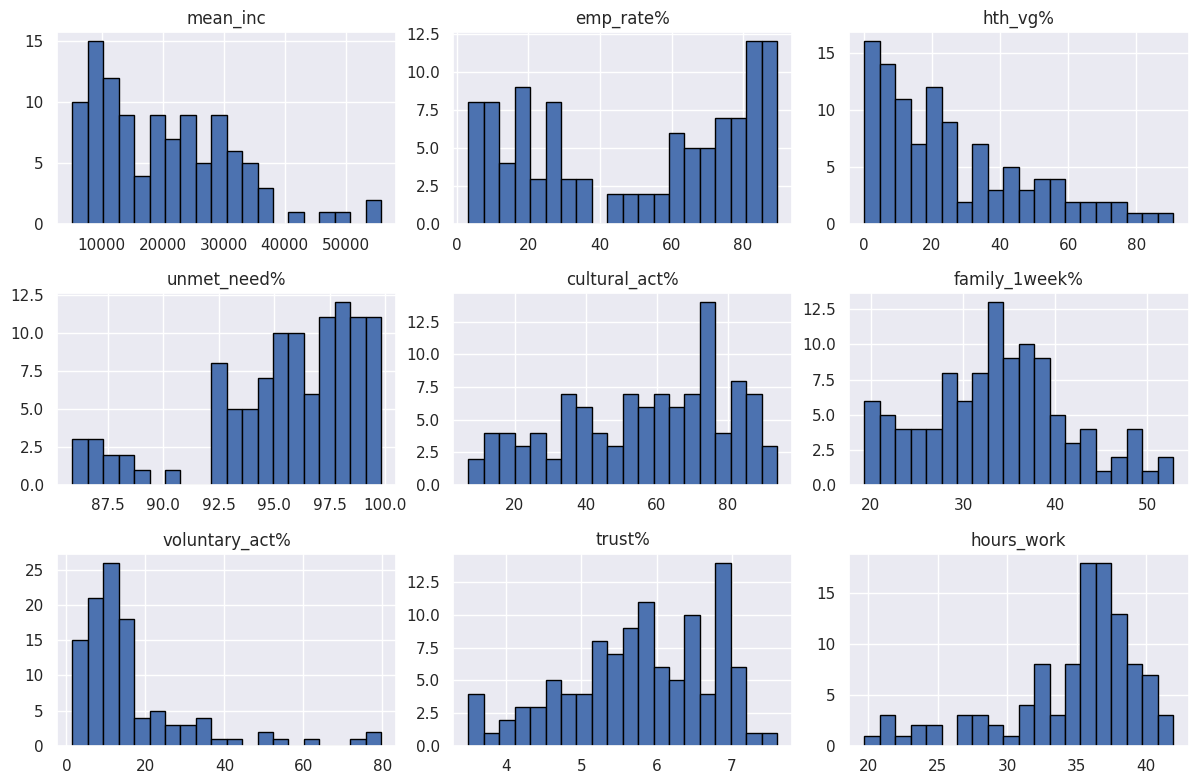

In [76]:
sns.set()
df_1[numeric_cols].hist(
    bins=20,
    figsize=(12,8),
    edgecolor = "black"
)

plt.tight_layout()
plt.show()


In [84]:
# Standardize the data

scaler = StandardScaler()
df_standardized = scaler.fit_transform(df_1[numeric_cols])

df_1_standardized = pd.DataFrame(df_standardized)
df_1_standardized.columns = numeric_cols
df_1_standardized.index = df_1.index

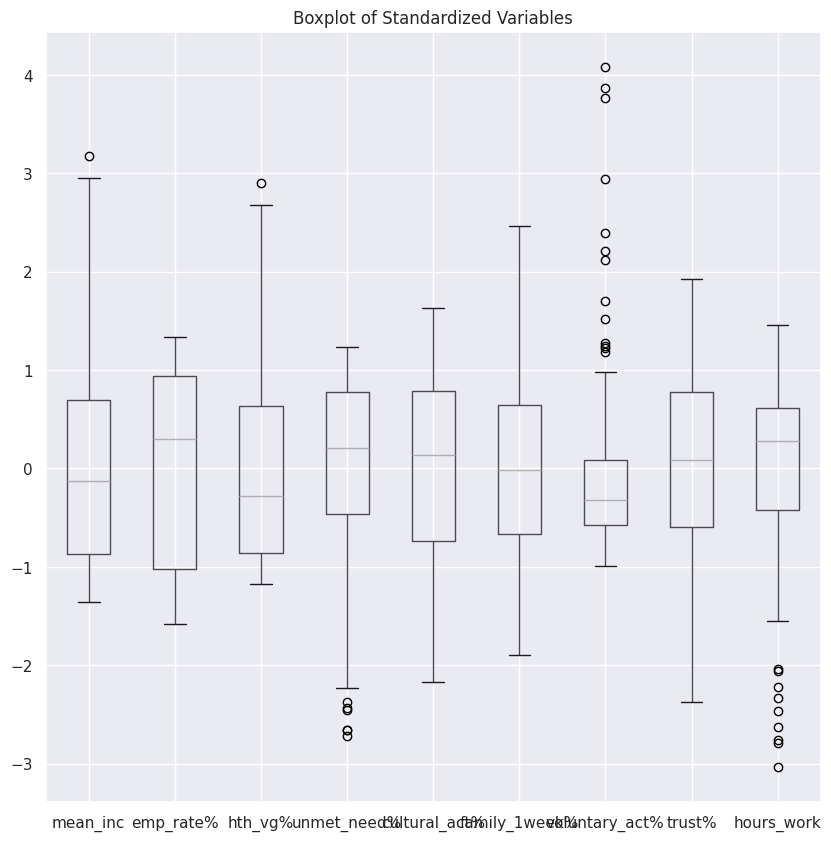

In [91]:
sns.set()
plt.figure(figsize=(10,10))
df_1_standardized[numeric_cols].boxplot()
plt.title('Boxplot of Standardized Variables')
plt.show()

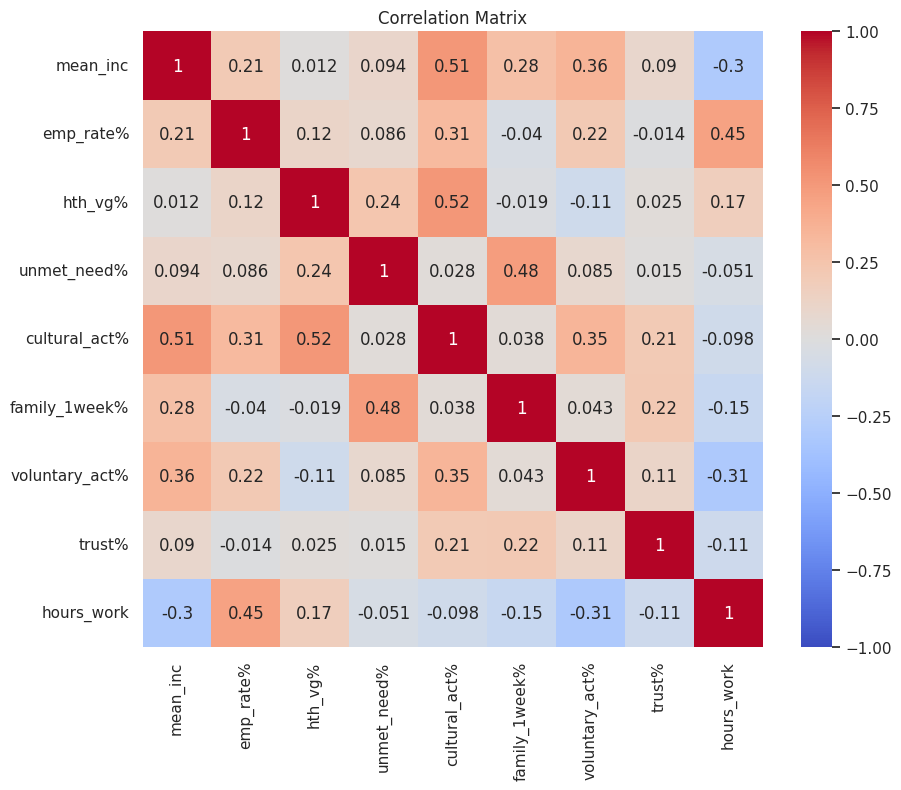

In [93]:
#Check correlations

corr_matrix = df_1_standardized.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

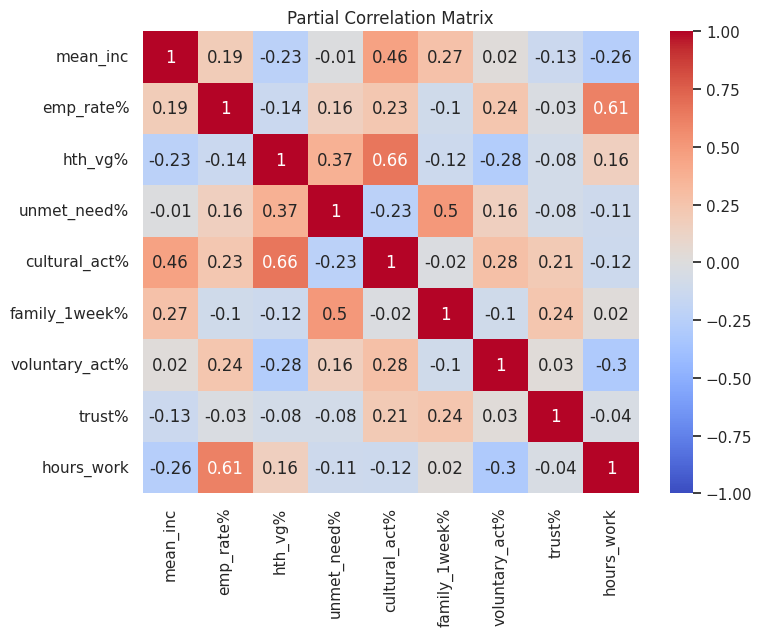

In [94]:
# Partial Correlation matrix

partial_corr_matrix = pd.DataFrame(index = numeric_cols, columns=numeric_cols)

for var1 in numeric_cols:
    for var2 in numeric_cols:
        if var1 == var2:
            partial_corr_matrix.loc[var1, var2] = 1.0
        else:
            covariates = [col for col in numeric_cols if col not in [var1, var2]]
            result = pg.partial_corr(data=df_1_standardized, x=var1, y=var2, covar=covariates)
            partial_corr_matrix.loc[var1, var2] = result['r'].values[0]

partial_corr_matrix = partial_corr_matrix.astype(float)

plt.figure(figsize=(8, 6))
sns.heatmap(partial_corr_matrix.round(2), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Partial Correlation Matrix')
plt.show()

In [96]:
#KMO
kmo_all, kmo_model = calculate_kmo(df_1_standardized)

#Overall KMO
print(f"Overall KMO: {kmo_model:.2f}")

#Individual KMO
kmo_all_series = pd.Series(kmo_all, index = numeric_cols)
print("\nIndividual KMO:")
print(kmo_all_series.round(2))

Overall KMO: 0.46

Individual KMO:
mean_inc          0.58
emp_rate%         0.42
hth_vg%           0.33
unmet_need%       0.38
cultural_act%     0.47
family_1week%     0.48
voluntary_act%    0.55
trust%            0.48
hours_work        0.44
dtype: float64


#Factor Analysis




In [97]:
#Initialize Factor Analysis

fa = FactorAnalyzer(n_factors=9, rotation = None)
#we indicate the number of variables we're going to use, we start with none to then analyse the other possible outcomes
fa.fit(df_1_standardized)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(n_factors=9, rotation=None, rotation_kwargs={})

In [98]:
#Kaiser Criterion

eigenvalues, _ = fa.get_eigenvalues()
print("Eigenvalues:\n", eigenvalues)
#eigenvalues must be higher than 1.


Eigenvalues:
 [2.27978536 1.69640607 1.39964512 1.09984088 0.95976666 0.70361102
 0.38087411 0.28014024 0.19993053]


In [99]:
#Pearson Criterion

variance_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_variance = np.cumsum(variance_ratio)
print("Cumulative variance explained:")
print(cumulative_variance)
#retain 80% of variance


Cumulative variance explained:
[0.25330948 0.44179905 0.59731517 0.71951972 0.82616046 0.90433946
 0.9466588  0.9777855  1.        ]


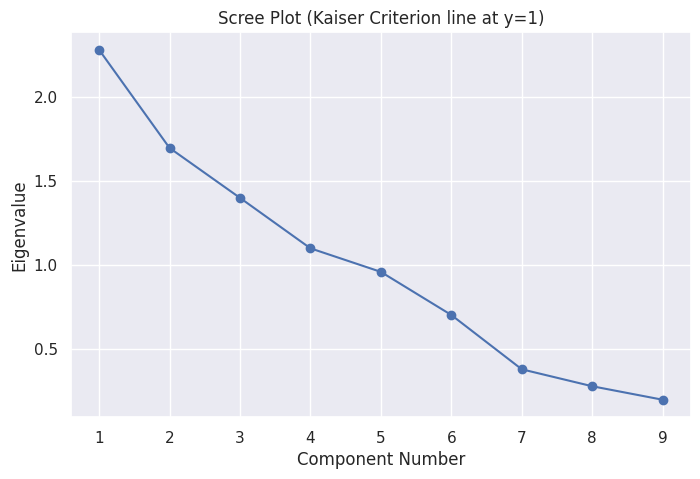

In [100]:
#Scree Plot

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues)+1), eigenvalues, marker='o')
plt.title('Scree Plot (Kaiser Criterion line at y=1)')
plt.xlabel('Component Number')
plt.ylabel('Eigenvalue')
plt.grid(True)
plt.show()
#elbow -1
#keep 3

In [101]:
#Perform FA with the number of factors you want to retain

n_factors = 4
fa = FactorAnalyzer(n_factors, rotation = None, method = "principal")
fa.fit(df_1_standardized)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


FactorAnalyzer(method='principal', n_factors=4, rotation=None,
               rotation_kwargs={})

In [102]:
#Loadings
loadings = fa.loadings_

loadings_df = pd.DataFrame(loadings, index = numeric_cols, columns = ["F1","F2","F3","F4"])
loadings_df

,F1,F2,F3,F4
mean_inc,0.751492,-0.134077,-0.211215,0.145901
emp_rate%,0.343661,0.673508,-0.093918,0.535915
hth_vg%,0.332014,0.555441,0.310420,-0.607223
unmet_need%,0.370675,-0.064651,0.752459,0.187322
cultural_act%,0.780058,0.343058,-0.216352,-0.333438
family_1week%,0.422006,-0.366904,0.641092,0.222906
voluntary_act%,0.594289,-0.176273,-0.424035,0.294654
trust%,0.337785,-0.179167,0.066069,-0.256575
hours_work,-0.308952,0.772426,0.204155,0.272064


In [104]:
#Communalities

communalities = fa.get_communalities()
print("Communalities:\n", communalities)
#we need communalities higher than 0,5

Communalities:
 [0.64861559 0.86774112 0.88382871 0.74286435 0.88416815 0.77339317
 0.65087909 0.21639592 0.80779134]


In [105]:
#RMSR

reconstructed_corr = np.dot(loadings, loadings.T)

residuals = corr_matrix.values - reconstructed_corr

mask = ~np.eye(residuals.shape[0], dtype=bool)

rmsr = np.sqrt(np.mean(residuals[mask]**2))

print(f"RMSR: {rmsr:.4f}")


RMSR: 0.0929
